# Phân tích dữ liệu thô (EDA): corpus tin tức vi phạm pháp luật

Notebook này khảo sát 3 file gốc `train/val/test_cleaned_labeled.csv` **trước khi** chạy pipeline làm sạch
(`data_pipeline/step1` → `step7`). Mục tiêu là trả lời:

1. Dữ liệu có bao nhiêu bài, những cột gì, có ô trống không?
2. Nhãn `Label` / `SubLabel` phân bố thế nào, có mất cân bằng không, có mâu thuẫn không?
3. Bài báo dài bao nhiêu, có vượt giới hạn của PhoBERT không?
4. Văn bản có những lỗi gì (mã hóa Unicode, ký tự ẩn, chú thích ảnh, URL, khoảng trắng trước dấu câu)?
5. Có bài trùng lặp trong cùng tập, hoặc rò rỉ giữa train/val/test không?
6. Từ vựng và từ khóa trigger khác nhau thế nào giữa các nhóm vi phạm?
7. Sau từng bước pipeline, dữ liệu còn lại bao nhiêu?

Mỗi phần đều kèm nhận xét để dùng cho báo cáo. Đặt notebook trong `notebooks/`, dữ liệu trong `data/corpus news/`.

In [1]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("../data/corpus news")
SPLITS = ["train", "val", "test"]

raw = {sp: pd.read_csv(DATA_DIR / f"{sp}_cleaned_labeled.csv", encoding="utf-8") for sp in SPLITS}
for sp, df in raw.items():
    print(f"{sp:5s}: {df.shape[0]:>6,} bài, cột = {list(df.columns)}")

train: 30,968 bài, cột = ['Summarize', 'Content', 'Label', 'SubLabel']
val  :  4,424 bài, cột = ['Summarize', 'Content', 'Label', 'SubLabel']
test :  8,848 bài, cột = ['Summarize', 'Content', 'Label', 'SubLabel']


## 1. Tổng quan và ô trống

In [2]:
rows = []
for sp, df in raw.items():
    for col in df.columns:
        s = df[col]
        rows.append({"tap": sp, "cot": col, "kieu": str(s.dtype),
                     "NaN": int(s.isna().sum()),
                     "chuoi_rong": int((s.astype(str).str.strip() == "").sum()),
                     "so_gia_tri_khac_nhau": int(s.nunique())})
overview = pd.DataFrame(rows)
overview

,tap,cot,kieu,NaN,chuoi_rong,so_gia_tri_khac_nhau
0,train,Summarize,str,0,0,30960
1,train,Content,str,0,0,30968
2,train,Label,str,0,0,2
3,train,SubLabel,str,0,0,6
4,val,Summarize,str,0,0,4424
5,val,Content,str,0,0,4424
6,val,Label,str,0,0,2
7,val,SubLabel,str,0,0,6
8,test,Summarize,str,0,0,8848
9,test,Content,str,0,0,8848


In [3]:
total = sum(len(df) for df in raw.values())
print("Tổng số bài:", f"{total:,}")
print("Tỷ lệ chia:", {sp: f"{len(df) / total:.1%}" for sp, df in raw.items()})
raw["train"].head(3)

Tổng số bài: 44,240
Tỷ lệ chia: {'train': '70.0%', 'val': '10.0%', 'test': '20.0%'}


,Summarize,Content,Label,SubLabel
0,"Người đưa, môi giới hoặc nhận “hối lộ tình dục”, “đổi tình lấy chức”… bị xử lý hình sự như nhận tài sản, tiền bạc.","Người đưa, môi giới hoặc nhận “hối lộ tình dục”, “đổi tình lấy chức”… bị xử lý hình sự như nhận tài sản, tiền bạc. T...",Vi phạm pháp luật,Tội phạm Kinh tế / Tham nhũng
1,"Nghĩ em vợ hỗn láo với mình, Bặc đã về nhà lấy một con dao bầu rồi truy sát Mạnh, kết quả là Mạnh đã bị một vết dao ...","- Nghĩ em vợ hỗn láo với mình, Bặc đã về nhà lấy một con dao bầu rồi truy sát Mạnh, kết quả là Mạnh đã bị một vết da...",Vi phạm pháp luật,Tội phạm Trật tự xã hội / Hình sự
2,"Với thời gian tiến hành từ 8h sáng tới 17h chiều , buổi khám xét nhà Bùi Văn Công có lẽ sẽ đi vào kỷ lục trình tự tố...","Sáng nay 23/3 , Cơ quan cảnh sát điều tra Công an tỉnh Điện Biên phối hợp cùng VKSND tỉnh đã tổ chức khám nghiệm lần...",Vi phạm pháp luật,Tội phạm Ma túy


**Nhận xét:** dữ liệu có 44.240 bài, chia sẵn train/val/test theo tỷ lệ 70/10/20, gồm 4 cột: `Summarize` (tóm tắt / sapo),
`Content` (nội dung bài), `Label` (vi phạm hay không) và `SubLabel` (nhóm vi phạm). Không có ô trống. Nhãn ở **mức bài báo**,
không có nhãn thực thể hay sự kiện, nên nhóm phải tự gán nhãn ở mức câu cho 2 luồng NER và Event.

## 2. Phân bố nhãn

In [4]:
def dist(col):
    t = pd.concat({sp: df[col].value_counts() for sp, df in raw.items()}, axis=1).fillna(0).astype(int)
    pct = (t / t.sum() * 100).round(1).add_suffix(" %")
    return pd.concat([t, pct], axis=1)

dist("Label")

,train,val,test,train %,val %,test %
Label,,,,,,
Vi phạm pháp luật,25672,3639,7428,82.9,82.3,84.0
Khác,5296,785,1420,17.1,17.7,16.0


In [5]:
sub = dist("SubLabel")
sub

,train,val,test,train %,val %,test %
SubLabel,,,,,,
Vi phạm pháp luật khác,10466,1472,3025,33.8,33.3,34.2
Tội phạm Trật tự xã hội / Hình sự,8188,1148,2337,26.4,25.9,26.4
Khác (Không vi phạm),5050,749,1349,16.3,16.9,15.2
Tội phạm Kinh tế / Tham nhũng,3595,530,1090,11.6,12.0,12.3
Tội phạm Ma túy,2794,373,799,9.0,8.4,9.0
Vi phạm Giao thông,875,152,248,2.8,3.4,2.8


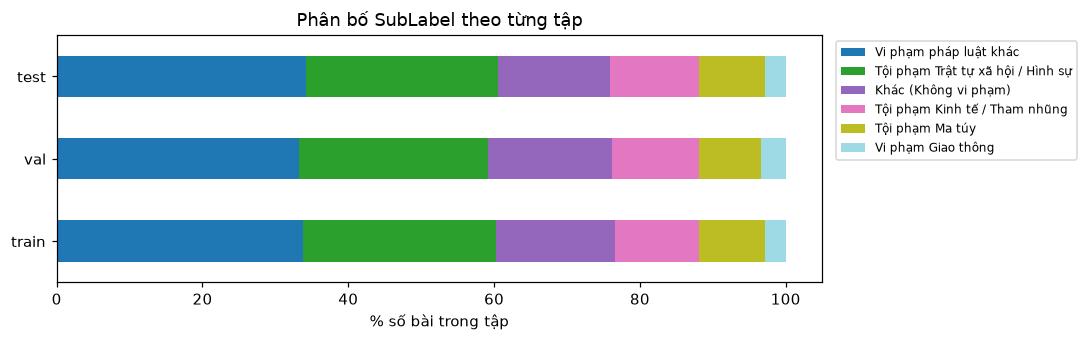

In [6]:
ax = sub[[sp for sp in SPLITS]].div(sub[SPLITS].sum()).mul(100).T.plot(
    kind="barh", stacked=True, figsize=(10, 3.2), colormap="tab20")
ax.set_xlabel("% số bài trong tập")
ax.set_title("Phân bố SubLabel theo từng tập")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# Mâu thuẫn: Label = "Khác" nhưng SubLabel lại là một nhóm vi phạm (và ngược lại)
NO_VIOL = "Khác (Không vi phạm)"
for sp, df in raw.items():
    a = ((df["Label"] == "Khác") & (df["SubLabel"] != NO_VIOL)).sum()
    b = ((df["Label"] != "Khác") & (df["SubLabel"] == NO_VIOL)).sum()
    print(f"{sp:5s}: Label=Khác nhưng SubLabel là vi phạm: {a:>4} | Label=vi phạm nhưng SubLabel=Khác: {b:>4}")
pd.crosstab(raw["train"]["Label"], raw["train"]["SubLabel"])

train: Label=Khác nhưng SubLabel là vi phạm:  246 | Label=vi phạm nhưng SubLabel=Khác:    0
val  : Label=Khác nhưng SubLabel là vi phạm:   36 | Label=vi phạm nhưng SubLabel=Khác:    0
test : Label=Khác nhưng SubLabel là vi phạm:   71 | Label=vi phạm nhưng SubLabel=Khác:    0


SubLabel,Khác (Không vi phạm),Tội phạm Kinh tế / Tham nhũng,Tội phạm Ma túy,Tội phạm Trật tự xã hội / Hình sự,Vi phạm Giao thông,Vi phạm pháp luật khác
Label,,,,,,
Khác,5050,18,8,30,190,0
Vi phạm pháp luật,0,3577,2786,8158,685,10466


**Nhận xét:**
- Khoảng 83% số bài là "Vi phạm pháp luật", 17% là tin "Khác".
- Các nhóm SubLabel **mất cân bằng**: "Vi phạm pháp luật khác" chiếm khoảng 34%, "Trật tự xã hội / Hình sự" khoảng 26%,
  còn "Ma túy" khoảng 9% và "Vi phạm Giao thông" chỉ khoảng 3%. Nhóm Giao thông quá ít để huấn luyện và đánh giá riêng,
  nên bị bỏ ở bước 3 của pipeline (`EXCLUDE_SUBLABELS`).
- Phân bố giữa 3 tập gần như giống nhau (chênh nhau dưới 1 điểm %), nên việc chia tập có sẵn là chia phân tầng.
- Có **353 bài mâu thuẫn** (246 train, 36 val, 71 test): Label = "Khác" nhưng SubLabel lại là một nhóm vi phạm (phần lớn là
  "Vi phạm Giao thông"). Chiều ngược lại không có. Bước 2 sửa theo Label: Label = "Khác" thì SubLabel = "Khác (Không vi phạm)".

## 3. Độ dài văn bản

In [8]:
for df in raw.values():
    for col in ("Summarize", "Content"):
        df[f"n_words_{col}"] = df[col].fillna("").astype(str).str.split().str.len()
        df[f"n_chars_{col}"] = df[col].fillna("").astype(str).str.len()

lens = pd.concat({sp: df[["n_words_Summarize", "n_words_Content"]].describe(percentiles=[.25, .5, .75, .95, .99])
                  for sp, df in raw.items()}, axis=1).round(1)
lens

train                               val                              test                
      n_words_Summarize n_words_Content n_words_Summarize n_words_Content n_words_Summarize n_words_Content
count           30968.0         30968.0            4424.0          4424.0            8848.0          8848.0
mean               36.8           528.4              37.0           533.2              36.9           536.8
std                10.2           293.4              10.4           296.8              10.2           306.9
min                10.0            89.0              14.0           110.0              12.0           109.0
25%                29.0           313.0              29.0           314.0              29.0           315.0
50%                36.0           456.5              36.0           460.5              36.0           465.0
75%                43.0           679.0              44.0           684.2              43.0           689.0
95%                55.0          1074.0              55.0          1082.0              55.0          1085.6
99%                65.0          1431.0              65.0          1407.5              64.0          1483.5
max               159.0          4411.0             114.0          3326.0             110.0          6522.0

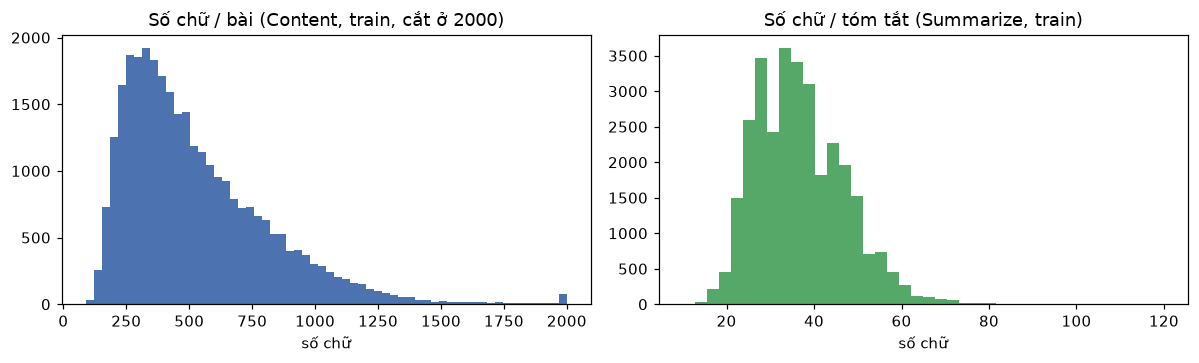

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
tr = raw["train"]
axes[0].hist(tr["n_words_Content"].clip(upper=2000), bins=60, color="#4C72B0")
axes[0].set_title("Số chữ / bài (Content, train, cắt ở 2000)")
axes[0].set_xlabel("số chữ")
axes[1].hist(tr["n_words_Summarize"].clip(upper=120), bins=40, color="#55A868")
axes[1].set_title("Số chữ / tóm tắt (Summarize, train)")
axes[1].set_xlabel("số chữ")
plt.tight_layout(); plt.show()

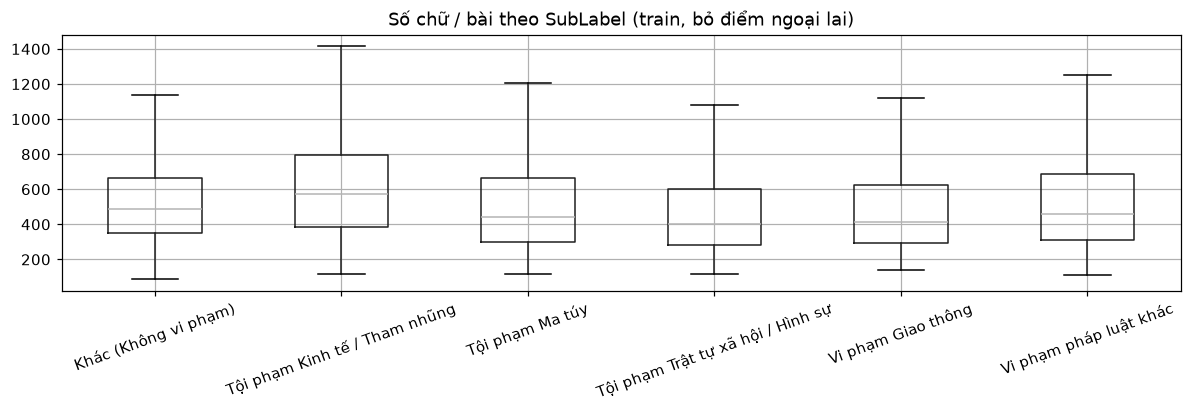

SubLabel
Tội phạm Trật tự xã hội / Hình sự    403.0
Vi phạm Giao thông                   415.0
Tội phạm Ma túy                      442.0
Vi phạm pháp luật khác               457.0
Khác (Không vi phạm)                 485.0
Tội phạm Kinh tế / Tham nhũng        575.0
Name: n_words_Content, dtype: float64

In [10]:
ax = tr.boxplot(column="n_words_Content", by="SubLabel", figsize=(11, 4), showfliers=False, rot=20)
ax.set_title("Số chữ / bài theo SubLabel (train, bỏ điểm ngoại lai)"); ax.set_xlabel(""); plt.suptitle("")
plt.tight_layout(); plt.show()
tr.groupby("SubLabel")["n_words_Content"].median().sort_values()

In [11]:
# Bài quá ngắn / rỗng và bài rất dài
for sp, df in raw.items():
    print(f"{sp:5s}: Content < 30 chữ: {(df['n_words_Content'] < 30).sum():>4} | "
          f"> 256 chữ (vượt PhoBERT nếu đưa cả bài): {(df['n_words_Content'] > 256).mean():.1%}")

train: Content < 30 chữ:    0 | > 256 chữ (vượt PhoBERT nếu đưa cả bài): 85.8%
val  : Content < 30 chữ:    0 | > 256 chữ (vượt PhoBERT nếu đưa cả bài): 86.2%
test : Content < 30 chữ:    0 | > 256 chữ (vượt PhoBERT nếu đưa cả bài): 85.7%


**Nhận xét:**
- Một bài dài trung vị khoảng 460 chữ (95% số bài dưới khoảng 1.080 chữ). Khoảng **86% số bài dài hơn 256 chữ**, tức vượt giới
  hạn đầu vào của PhoBERT nếu đưa cả bài. Do đó cả 2 luồng đều làm ở **mức câu**: bước 4 tách bài thành câu và giữ câu dài 5–100 chữ.
- Bài nhóm Kinh tế / Tham nhũng dài nhất (trung vị 575 chữ), nhóm Trật tự xã hội ngắn nhất (403 chữ).
- Phần tóm tắt ngắn (trung vị 36 chữ) và thường lặp lại câu đầu của `Content`, nên bước 4 bỏ câu đầu nếu nó trùng tóm tắt.

## 4. Lỗi văn bản: mã hóa, ký tự ẩn, nhiễu

In [12]:
PATTERNS = {
    "dau_roi (combining mark)": re.compile("[\u0300-\u036f]"),
    "ky_tu_an (zero-width/BOM/soft hyphen)": re.compile("[\u200b\ufeff\u00ad]"),
    "ky_tu_hong (\\ufffd)": re.compile("\ufffd"),
    "chu_thich_anh ('Ảnh :')": re.compile(r"(?:Ảnh|Đồ họa|Đồ hoạ)\s*:"),
    "XEM CLIP": re.compile(r"(?:XEM CLIP|Xem [Cc]lip)\s*:"),
    "URL": re.compile(r"https?://\S+|www\.\S+"),
    "khoang_trang_truoc_dau (' ,' ' .')": re.compile(r"\s[,.;:!?]"),
}

def issue_table(col="Content"):
    rows = []
    for sp, df in raw.items():
        text = df[col].fillna("").astype(str)
        row = {"tap": sp}
        for name, rx in PATTERNS.items():
            row[name] = f"{text.str.contains(rx).mean():.1%}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("tap").T

issue_table("Content")

tap,train,val,test
dau_roi (combining mark),5.9%,5.2%,5.8%
ky_tu_an (zero-width/BOM/soft hyphen),0.2%,0.3%,0.2%
ky_tu_hong (\ufffd),0.0%,0.0%,0.0%
chu_thich_anh ('Ảnh :'),11.1%,11.8%,10.7%
XEM CLIP,0.9%,0.9%,0.8%
URL,0.2%,0.1%,0.1%
"khoang_trang_truoc_dau (' ,' ' .')",46.4%,47.1%,46.2%


In [13]:
# Ví dụ cụ thể cho từng loại lỗi (train)
text = raw["train"]["Content"].fillna("").astype(str)
for name, rx in PATTERNS.items():
    hit = text[text.str.contains(rx)]
    if len(hit):
        s = hit.iloc[0]; m = rx.search(s)
        print(f"[{name}] ...{s[max(0, m.start() - 50):m.end() + 50]!r}...")

[dau_roi (combining mark)] ...'iền cùng dây chuyền, tổng cộng 4,4 triệu đồng. Ngày 23/8, thấy H. mất dây chuyền nên gia đình phát h'...
[ky_tu_an (zero-width/BOM/soft hyphen)] ...'nay, các tài khoản này đã gỡ hình ảnh và nội dung.\u200b Một tài khoản Facebook giả mạo IS đưa tin khiêu k'...
[ky_tu_hong (\ufffd)] ...' sư TP HCM) đã có đơn xin hoãn phiên tòa vì lý do �bận việc gia đình� đột xuất. Sau khi hội ý, HĐXX đ'...
[chu_thich_anh ('Ảnh :')] ...'h (giữa) chủ trì hội nghị tại đầu cầu Quảng Ngãi. Ảnh: CTV Không xử hình sự hành vi tảo hôn Liên quan đế'...
[XEM CLIP] ...'ghỉ hưu về hành vi “Cố ý làm lộ bí mật nhà nước". XEM CLIP: Khám nhà cựu Tổng cục phó Tổng cục 5 Phan Hữu Tuấ'...
[URL] ...'rang web của Cục đăng kiểm Việt Nam tại địa chỉ : http://www.vr.org.vn .'...
[khoang_trang_truoc_dau (' ,' ' .')] ...'Sáng nay 23/3 , Cơ quan cảnh sát điều tra Công an tỉnh Điện Biên '...


In [14]:
# Văn bản ở dạng NFC chưa? (NFC = dấu tiếng Việt dựng sẵn, chuẩn cho tokenizer)
for sp, df in raw.items():
    t = df["Content"].fillna("").astype(str)
    not_nfc = (t != t.map(lambda x: unicodedata.normalize("NFC", x))).mean()
    print(f"{sp:5s}: {not_nfc:.2%} bài chưa ở dạng NFC")

train: 5.87% bài chưa ở dạng NFC
val  : 5.15% bài chưa ở dạng NFC
test : 5.75% bài chưa ở dạng NFC


**Nhận xét:** văn bản có nhiều kiểu nhiễu:
- **Khoảng trắng trước dấu câu** ("23/3 , Cơ quan") có ở khoảng **46% số bài**: một phần dữ liệu đã bị tách token sẵn, phần còn
  lại là văn bản tự nhiên, tức có 2 kiểu văn bản lẫn nhau. Bước 4 đưa về một dạng.
- **Chú thích ảnh** ("Ảnh: CTV") có ở khoảng **11% số bài**, "XEM CLIP" khoảng 1%, URL khoảng 0,2%. Bước 2 xóa đi để không tạo ra "câu" rác.
- **Dấu tiếng Việt dạng rời** (chưa ở dạng NFC) có ở khoảng **6% số bài**. Nhìn bằng mắt giống hệt nhau, nhưng tokenizer coi là
  chữ khác, nên "Kỳ" viết rời sẽ không khớp từ điển. Ký tự ẩn (0,2%) và ký tự hỏng "�" rất ít. Bước 1 chuẩn hóa NFC và xóa ký tự ẩn.

## 5. Trùng lặp và rò rỉ giữa các tập

In [15]:
def norm_key(s):
    return re.sub(r"\W+", " ", str(s).lower()).strip()

keys = {}
for sp, df in raw.items():
    c = df["Content"].fillna("").map(norm_key)
    keys[sp] = {"full": set(c), "head": set(c.str[:200]), "sum": set(df["Summarize"].fillna("").map(norm_key))}
    print(f"{sp:5s}: trùng nội dung trong tập: {c.duplicated().sum():>4} | "
          f"trùng 200 ký tự đầu: {c.str[:200].duplicated().sum():>4} | "
          f"trùng tiêu đề/tóm tắt: {df['Summarize'].fillna('').map(norm_key).duplicated().sum():>4}")

train: trùng nội dung trong tập:    0 | trùng 200 ký tự đầu:   29 | trùng tiêu đề/tóm tắt:   10
val  : trùng nội dung trong tập:    0 | trùng 200 ký tự đầu:    1 | trùng tiêu đề/tóm tắt:    0
test : trùng nội dung trong tập:    0 | trùng 200 ký tự đầu:    4 | trùng tiêu đề/tóm tắt:    0


In [16]:
pairs = [("train", "val"), ("train", "test"), ("val", "test")]
rows = []
for a, b in pairs:
    rows.append({"cap": f"{a} ∩ {b}",
                 "trung_noi_dung": len(keys[a]["full"] & keys[b]["full"]),
                 "trung_200_ky_tu_dau": len(keys[a]["head"] & keys[b]["head"]),
                 "trung_tom_tat": len(keys[a]["sum"] & keys[b]["sum"])})
pd.DataFrame(rows).set_index("cap")

,trung_noi_dung,trung_200_ky_tu_dau,trung_tom_tat
cap,,,
train ∩ val,0,7,3
train ∩ test,1,14,4
val ∩ test,0,3,0


**Nhận xét:** không có bài trùng y hệt nội dung, nhưng có các bài **gần trùng** (cùng một tin đăng lại, chỉ sửa nhẹ phần sau):
29 bài trong train trùng 200 ký tự đầu, và có bài **trùng giữa các tập** (14 cặp train–test, 7 cặp train–val, 3 cặp val–test
theo 200 ký tự đầu). Số lượng nhỏ, nhưng nếu giữ nguyên thì mô hình được "nhìn thấy" bài test lúc train (rò rỉ dữ liệu).
Bước 2 xử lý: giữ nguyên test, bỏ khỏi val các bài trùng test, bỏ khỏi train các bài trùng val/test. Hai bài coi là trùng khi
giống nội dung, giống 200 ký tự đầu, hoặc giống tóm tắt.

## 6. Từ vựng và từ khóa trigger theo nhóm

In [17]:
STOP = set("""và của là có được cho các những với trong khi này đã không một người đến tại theo về để từ
ra nhiều sau cũng như thì vào lại rằng nên đó họ đang bị tới mà sẽ nhưng còn hơn trên năm ngày ông bà anh chị
""".split())

def top_words(texts, k=15):
    cnt = Counter()
    for t in texts:
        for w in re.findall(r"[^\W\d_]+", str(t).lower()):
            if len(w) > 1 and w not in STOP:
                cnt[w] += 1
    return cnt.most_common(k)

sample = pd.concat([g.sample(min(len(g), 1500), random_state=42) for _, g in tr.groupby("SubLabel")])
pd.DataFrame({g: [f"{w} ({c})" for w, c in top_words(d["Content"])]
              for g, d in sample.groupby("SubLabel")})

,Khác (Không vi phạm),Tội phạm Kinh tế / Tham nhũng,Tội phạm Ma túy,Tội phạm Trật tự xã hội / Hình sự,Vi phạm Giao thông,Vi phạm pháp luật khác
0,công (3945),công (11228),công (9573),công (6749),xe (4304),công (8193)
1,bộ (2666),đồng (8420),an (8135),an (6075),công (3340),an (4671)
2,nhà (2656),tiền (7109),ma (7498),vụ (3599),thông (2977),đồng (3819)
3,hiện (2609),cáo (7052),đối (5036),nhà (3355),nạn (2882),quan (3688)
4,nam (2471),an (5219),túy (4325),đi (3340),đường (2555),định (3647)
5,việc (2423),án (5203),tra (4199),nhân (3323),vụ (2342),việc (3594)
6,thành (2321),quan (5121),tượng (4182),điều (3287),an (2282),vụ (3531)
7,đồng (2305),vụ (4973),hiện (3765),hiện (3283),giao (2254),cáo (3454)
8,ảnh (2302),tài (4938),điều (3686),quan (3162),tai (2000),hiện (3168)
9,sự (2289),định (4549),quan (3649),đối (3120),nhân (1941),điều (3157)


In [18]:
# Tần suất từ khóa trigger (theo TRIGGER_LEXICON trong data_pipeline/config.py) theo nhóm
LEXICON = {
    "LUA_DAO": ["lừa đảo", "chiếm đoạt"],
    "MA_TUY": ["mua bán trái phép", "tàng trữ", "vận chuyển", "ma túy"],
    "BAO_LUC": ["giết", "sát hại", "đâm", "chém", "đánh"],
    "CUOP_TROM": ["cướp", "trộm"],
    "BAT_GIU": ["bắt giữ", "bắt quả tang", "tạm giữ", "tạm giam"],
    "THU_GIU": ["thu giữ", "tịch thu"],
    "KHOI_TO": ["khởi tố", "truy tố"],
    "XET_XU": ["xét xử", "tuyên phạt", "tuyên án"],
}
rows = {}
for g, d in sample.groupby("SubLabel"):
    text = d["Content"].fillna("").str.lower()
    rows[g] = {et: f"{text.str.contains('|'.join(map(re.escape, kws))).mean():.0%}" for et, kws in LEXICON.items()}
pd.DataFrame(rows)

,Khác (Không vi phạm),Tội phạm Kinh tế / Tham nhũng,Tội phạm Ma túy,Tội phạm Trật tự xã hội / Hình sự,Vi phạm Giao thông,Vi phạm pháp luật khác
LUA_DAO,0%,74%,8%,2%,0%,3%
MA_TUY,2%,6%,78%,2%,3%,5%
BAO_LUC,20%,22%,40%,80%,15%,24%
CUOP_TROM,0%,8%,21%,39%,0%,0%
BAT_GIU,0%,43%,68%,48%,14%,31%
THU_GIU,0%,9%,38%,9%,1%,9%
KHOI_TO,0%,52%,26%,25%,16%,29%
XET_XU,1%,43%,21%,22%,11%,21%


**Nhận xét:**
- Bảng từ vựng đếm theo **âm tiết** (tiếng Việt chưa tách từ), nên "công an" tách thành "công" và "an". Dù vậy mỗi nhóm vẫn có
  từ đặc trưng rõ: "ma", "túy" ở nhóm Ma túy; "đồng", "tiền", "tài" (sản) ở nhóm Kinh tế; "xe", "đường", "tai" (nạn) ở nhóm Giao thông.
- Từ khóa **phạm tội** gắn chặt với nhóm tương ứng: "lừa đảo / chiếm đoạt" có ở 74% bài Kinh tế, từ khóa ma túy ở 78% bài
  Ma túy, từ khóa bạo lực ở 80% bài Trật tự xã hội.
- Từ khóa **tố tụng** (bắt giữ, khởi tố, xét xử) xuất hiện rải rác ở mọi nhóm vi phạm (20–70%). Vì vậy schema tách 2 nhóm
  sự kiện: 4 loại phạm tội (LUA_DAO, MA_TUY, BAO_LUC, CUOP_TROM) và 4 loại tố tụng (BAT_GIU, THU_GIU, KHOI_TO, XET_XU).
- Tin "Khác" gần như không có từ khóa tố tụng, nhưng 20% có từ khóa bạo lực. Lý do là từ khóa đơn như "đánh" còn khớp "đánh giá",
  "đánh bắt". Đây là lý do baseline từ khóa có nhiều trigger thừa, và quy ước gán nhãn phải liệt kê các cụm không phải trigger.
- Một bài có nhiều loại sự kiện cùng lúc, nên không thể dùng SubLabel của bài làm nhãn cho từng câu.

## 7. Dữ liệu còn lại qua từng bước pipeline

In [19]:
def n_rows(name):
    p = DATA_DIR / name
    return len(pd.read_csv(p, encoding="utf-8-sig", usecols=[0])) if p.exists() else None

funnel = pd.DataFrame({sp: {
    "0. gốc (bài)": len(raw[sp]),
    "1. sửa mã hóa (bài)": n_rows(f"{sp}_clean.csv"),
    "2-3. bỏ trùng/rò rỉ + bỏ Giao thông (bài)": n_rows(f"{sp}.csv"),
    "4. tách câu, lọc 5-100 chữ (câu)": n_rows(f"{sp}_sentences.csv"),
} for sp in SPLITS})
funnel

,train,val,test
0. gốc (bài),30968,4424,8848
1. sửa mã hóa (bài),30968,4424,8848
2-3. bỏ trùng/rò rỉ + bỏ Giao thông (bài),30223,4294,8653
"4. tách câu, lọc 5-100 chữ (câu)",418287,60034,123281


In [20]:
annot_dir = Path("../data/dataset")
if annot_dir.exists():
    import json
    rows = {}
    for sp in SPLITS:
        p = annot_dir / f"{sp}.jsonl"
        if p.exists():
            recs = [json.loads(l) for l in p.open(encoding="utf-8")]
            ents = Counter(e["label"] for r in recs for e in r["entities"])
            trig = Counter(t["label"] for r in recs for t in r["triggers"])
            rows[sp] = {"câu gán tay": len(recs),
                        "câu có trigger": sum(bool(r["triggers"]) for r in recs),
                        "thực thể": sum(ents.values()), "trigger": sum(trig.values()),
                        "quan hệ": sum(len(r["relations"]) for r in recs)}
    display(pd.DataFrame(rows))

**Nhận xét:**
- Bước 1 không làm mất bài nào, chỉ sửa ký tự. Bước 2–3 bỏ 1.070 bài (trùng, rò rỉ và nhóm Giao thông), còn 43.170 bài.
- Bước 4 tách được khoảng **601 nghìn câu** sạch (418.287 / 60.034 / 123.281).
- Vì không thể gán tay hết, nhóm lấy mẫu câu (chia đều theo SubLabel, tối đa 2 câu mỗi bài). Train ưu tiên 50% câu có từ khóa
  trigger, còn val/test lấy ngẫu nhiên để đánh giá công bằng. Kết quả đã gán tay: train 301, val 150, test 150 câu.
- Trên test lấy ngẫu nhiên, chỉ 42/150 câu (28%) có sự kiện. Trên train (có ưu tiên từ khóa) tỷ lệ là 53%. Điều này khớp với
  lý do lấy mẫu có ưu tiên cho train: nếu lấy ngẫu nhiên, mô hình có quá ít ví dụ trigger để học.

## Tóm tắt cho báo cáo

| Vấn đề phát hiện | Xử lý trong pipeline |
|---|---|
| Nhãn chỉ ở mức bài, không có nhãn thực thể/sự kiện | Tách câu và gán nhãn tay mức câu (Label Studio) |
| Bài dài, vượt giới hạn PhoBERT | Tách câu, giữ câu 5–100 chữ (bước 4) |
| Nhiễu: chú thích ảnh, "XEM CLIP", URL | Xóa bằng regex (bước 2) |
| Lỗi mã hóa: dấu rời, ký tự ẩn, ký tự hỏng | Chuẩn hóa NFC, xóa ký tự ẩn (bước 1) |
| Khoảng trắng trước dấu câu do dữ liệu tách token sẵn | Đưa về văn bản tự nhiên (bước 4) |
| Label và SubLabel mâu thuẫn | Sửa theo Label (bước 2) |
| Bài trùng trong tập và giữa các tập | Bỏ trùng, chống rò rỉ val/test (bước 2) |
| "Vi phạm Giao thông" quá ít | Bỏ khỏi phạm vi (bước 3) |